# Stream 5: Ordering simulation (what stockout correction is worth in dollars)

**Project:** Stockout-Aware Demand Forecasting for Grocery Retail (MIS 382N)

**The one question this notebook answers:** if a store orders perishables from these forecasts every day, how much money does it lose to empty shelves and to spoiled stock, and how much does training on *corrected demand* instead of *recorded sales* save?

**The plan, in plain English**
1. Load the forecasts streams 2 and 4 handed off: 4 models (seasonal naive, LightGBM, GRU, Chronos-2), each trained on raw sales and on corrected demand, over 5 backtest weeks.
2. Turn the cost assumptions into an ordering rule. Running out costs the margin ($0.30 a unit); leftover stock spoils overnight and costs what we paid for it ($0.70 a unit). Because waste hurts more than a lost sale, the best order is a bit *below* the median forecast: the 30th percentile.
3. Simulate each day: order, see true demand, count lost sales and waste, add up the dollars.
4. Compare raw vs. corrected for every model, check how sure we are, and test other margins.

**Decisions we made**
- **True demand = corrected demand v1** (`demand` in `daily_demand_v1.parquet`), as the plan says. Because the corrected models were trained on that same estimate, we also rerun everything with a low and a high version of true demand (Step 8) so the result doesn't rest on it.
- **All days count**, stockout days included. Stream 4 found in-stock-only scoring is biased (it drops exactly the days where demand was hidden), and a store pays for every day.
- **5 backtest weeks** (W1 to W4 in May and June, plus the test week), from `forecasts_stream4_backtest_v1.parquet`. Every model was retrained before each week and saw nothing from it.
- **No stock carried over**: fresh products spoil the next day, so each day is its own order.

## Step 0: Setup
Connect Google Drive (shared data) and pull the team repo (shared loader and metrics). No token is needed to read the repo; the last cell (for pushing) uses your `GITHUB_TOKEN` secret.

In [ ]:
# COLAB_ONLY
from google.colab import drive
import os
drive.mount('/content/drive')

repo = 'stockout-aware-forecasting'
if not os.path.exists(f'/content/{repo}'):
    !git clone https://github.com/bulut19/{repo}.git /content/{repo}
%cd /content/{repo}
!git pull

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
import warnings
warnings.filterwarnings('ignore')

from src.load_data import PROC_DIR
from src import metrics
# The loader picks the first Drive path that exists. STOCKOUT_PROC_DIR lets you point it somewhere else (e.g. a local copy).
PROC_DIR = Path(os.environ.get('STOCKOUT_PROC_DIR', PROC_DIR))

SEED = 42
N_DRAWS = 2000                 # bootstrap draws for the confidence check (same as stream 2)
PRICE = 1.00                   # every sales unit is worth $1 (the data has no prices)
MARGIN = 0.30                  # main case: 30% margin, so a unit costs $0.70
MARGINS = [0.20, 0.30, 0.40]   # sensitivity check
os.makedirs('figures', exist_ok=True)
os.makedirs('results/tables', exist_ok=True)
print('Data folder:', PROC_DIR)

Data folder: /tmp/claude-0/-home-user/347467f4-4f14-5040-b3bd-fd8ce56bfb54/scratchpad/data


## Step 1: Load the forecasts and true demand
- `forecasts_stream4_backtest_v1.parquet`: one row per product, day, model and version for the 5 backtest weeks. `forecast` is the point forecast; LightGBM and Chronos-2 also have `q10`, `q50`, `q90`.
- `forecasts_stream4_quantiles_v1.parquet`: Chronos-2 again, with finer ranges (5th to 95th percentile), so we can order exactly the 20th, 30th or 40th percentile.
- `daily_demand_v1.parquet`: recorded `sales` and corrected `demand` (our "true demand").

In [2]:
bt = pd.read_parquet(PROC_DIR / 'forecasts_stream4_backtest_v1.parquet')
fq = pd.read_parquet(PROC_DIR / 'forecasts_stream4_quantiles_v1.parquet')
dd = pd.read_parquet(PROC_DIR / 'daily_demand_v1.parquet')
for d in (bt, fq, dd):
    d['dt'] = pd.to_datetime(d['dt'])

# Short week names (W1 ... W4, Test) so both forecast files line up
bt['wk'] = bt['week'].str.split().str[0]
WEEKS = ['W1', 'W2', 'W3', 'W4', 'Test']
week_names = bt.drop_duplicates('wk').set_index('wk')['week'].reindex(WEEKS)
print(week_names.to_string())
print(f"\nBacktest file: {len(bt):,} rows | {bt.series_id.nunique():,} products | {bt.dt.nunique()} days")
print(bt.groupby(['model', 'version']).size().unstack().fillna(0).astype(int))

wk
W1           W1 May 15-21
W2           W2 May 22-28
W3        W3 May 29-Jun 4
W4            W4 Jun 5-11
Test    Test Jun 26-Jul 2

Backtest file: 630,000 rows | 2,000 products | 35 days
version         censored  corrected    raw
model                                     
chronos2               0      70000  70000
gru                70000      70000  70000
lightgbm               0      70000  70000
seasonal_naive         0      70000  70000


In [3]:
# Safety checks before simulating anything
# 1) Every model and version has every product on every backtest day
n_expected = bt.series_id.nunique() * bt.dt.nunique()
assert (bt.groupby(['model', 'version']).size() == n_expected).all(), 'a model is missing product-days'

# 2) The sales and demand columns in the forecast file match daily_demand_v1
chk = bt.merge(dd[['series_id', 'dt', 'sales', 'demand']], on=['series_id', 'dt'], suffixes=('', '_dd'))
assert len(chk) == len(bt)
assert np.allclose(chk.sales, chk.sales_dd) and np.allclose(chk.demand, chk.demand_dd)

# 3) Chronos-2's ranges in the two files agree (same run), and its point forecast is the median
ch = bt[bt.model == 'chronos2'].merge(fq[['series_id', 'dt', 'version', 'q50']], on=['series_id', 'dt', 'version'], suffixes=('', '_fine'))
gap = (ch.q50 - ch.q50_fine).abs()   # tiny float differences between the two runs are fine
assert len(ch) == len(fq) and gap.mean() < 1e-4 and gap.max() < 0.01 and np.allclose(ch.forecast, ch.q50)

# 4) Corrected demand is never below recorded sales
assert (dd.demand >= dd.sales - 1e-9).all()

days = bt[['series_id', 'dt', 'sales', 'demand', 'oos_hours']].drop_duplicates(['series_id', 'dt'])
print(f"Demand over the 5 weeks: {days.demand.sum():,.0f} units (recorded sales {days.sales.sum():,.0f}, "
      f"so {1 - days.sales.sum() / days.demand.sum():.1%} of demand was lost to empty shelves)")
print(f"Share of product-days with at least one empty-shelf hour: {(days.oos_hours > 0).mean():.1%}")
print('All checks passed.')

Demand over the 5 weeks: 82,708 units (recorded sales 71,707, so 13.3% of demand was lost to empty shelves)
Share of product-days with at least one empty-shelf hour: 39.7%
All checks passed.


## Step 2: The cost of guessing wrong (newsvendor rule)
Every morning the store orders a quantity **Q** of a fresh product, then demand **D** shows up:
- If **D > Q**, the shelf empties and the extra customers leave. Each lost unit costs the **margin** we didn't earn: $0.30.
- If **Q > D**, the leftover units spoil overnight. Each one costs what we **paid** for it: $0.70.

This is the classic *newsvendor* problem. The order that gives the lowest expected cost is the forecast percentile

$$\text{critical ratio} = \frac{\text{cost of a lost sale}}{\text{cost of a lost sale} + \text{cost of a spoiled unit}} = \frac{0.30}{0.30 + 0.70} = 0.30$$

So at a 30% margin the store should order the **30th percentile** of its forecast: enough to cover demand on 3 days in 10, because running short is cheaper than throwing food away. With a $1 price and cost = $1 minus the margin, the critical ratio is simply the margin (20% margin → 20th percentile, 40% → 40th).

*Note:* the plan says unsold units spoil "at their $0.70 cost". We keep cost = price − margin when the margin changes (so $0.80 at 20%, $0.60 at 40%). If you'd rather hold spoilage at $0.70, the ratios become 0.22 and 0.36; change `unit_cost` in `costs()` below.

In [4]:
def costs(margin, price=PRICE):
    # Dollar cost of one lost sale (underage) and one spoiled unit (overage)
    unit_cost = price * (1 - margin)
    under, over = price * margin, unit_cost
    return under, over, under / (under + over)

pd.DataFrame([dict(zip(['margin', 'lost sale costs', 'spoiled unit costs', 'order this percentile'],
                       [m, *costs(m)])) for m in MARGINS]).round(2)

,margin,lost sale costs,spoiled unit costs,order this percentile
0,0.2,0.2,0.8,0.2
1,0.3,0.3,0.7,0.3
2,0.4,0.4,0.6,0.4


## Step 3: The simulator
One function does the whole simulation. For every product-day it takes the order and true demand and returns units sold, lost and wasted, and what each cost. Nothing carries over to the next day.

In [5]:
def simulate(orders, margin=MARGIN, truth_col='demand', price=PRICE):
    # One row per product-day in, the same rows out with units and dollars added
    under, over, _ = costs(margin, price)
    D = orders[truth_col].clip(lower=0).to_numpy()
    Q = orders['order'].clip(lower=0).to_numpy()
    sold = np.minimum(Q, D)
    out = orders.copy()
    out['sold'] = sold
    out['lost_units'] = D - sold              # customers who found an empty shelf
    out['waste_units'] = Q - sold             # units that spoiled overnight
    out['lost_sales_usd'] = out.lost_units * under
    out['waste_usd'] = out.waste_units * over
    out['total_cost_usd'] = out.lost_sales_usd + out.waste_usd
    out['truth'] = D
    return out

def summarize(sim, by=('model', 'version', 'policy')):
    # Dollar totals per group, plus the share of demand served and cost as a share of revenue
    g = sim.groupby(list(by), observed=True)
    s = g[['lost_sales_usd', 'waste_usd', 'total_cost_usd', 'truth', 'sold']].sum()
    s['fill_rate'] = s.sold / s.truth
    s['cost_pct_of_demand'] = s.total_cost_usd / (s.truth * PRICE)
    return s.drop(columns=['sold']).rename(columns={'truth': 'demand_units'})

# Unit test on a tiny made-up example: demand 10 every day, orders 8, 10, 13
toy = pd.DataFrame({'order': [8.0, 10.0, 13.0], 'demand': [10.0, 10.0, 10.0]})
t = simulate(toy, margin=0.30)
assert np.allclose(t.lost_units, [2, 0, 0]) and np.allclose(t.waste_units, [0, 0, 3])
assert np.allclose(t.total_cost_usd, [0.6, 0.0, 2.1])
t[['order', 'demand', 'sold', 'lost_units', 'waste_units', 'total_cost_usd']]

,order,demand,sold,lost_units,waste_units,total_cost_usd
0,8.0,10.0,8.0,2.0,0.0,0.6
1,10.0,10.0,10.0,0.0,0.0,0.0
2,13.0,10.0,10.0,0.0,3.0,2.1


## Step 4: Build the orders
Each model and version gets two ordering rules:
- **Order the forecast** (`point`): order the model's single forecast. This is what a store does if it ignores the cost difference. Works for every model.
- **Order the critical percentile** (`newsvendor`): order the 30th percentile (or 20th / 40th in the sensitivity check). How we get that percentile depends on the model:
  - **Chronos-2:** read it straight from the fine-grained file.
  - **LightGBM:** stream 2 only trained the 10th, 50th and 90th percentiles. We draw a straight line between them (e.g. the 30th sits halfway between the 10th and 50th). Below we check how much that shortcut costs, using Chronos-2 where we know the real answer.
  - **Seasonal naive:** has no ranges, so we add one: *last week's value + the 30th percentile of how wrong "last week's value" was over the previous 28 days*, per product. It only uses data known on the order day.
  - **GRU:** point forecasts only, and we don't have its past errors before W1, so it only gets the `point` rule.

Every forecast used here was made with data up to 7 days before the target day, like the rest of the project.

In [6]:
KEEP = ['series_id', 'dt', 'wk', 'sales', 'demand', 'oos_hours', 'stockout_band']
info = bt.drop_duplicates(['series_id', 'dt'])[KEEP]

def interp_quantile(df, levels, tau):
    # Straight-line interpolation between known percentiles, e.g. levels {0.1: 'q10', 0.5: 'q50', 0.9: 'q90'}
    ls = sorted(levels)
    lo = max([l for l in ls if l <= tau], default=ls[0])
    hi = min([l for l in ls if l >= tau], default=ls[-1])
    if lo == hi:
        return df[levels[lo]].to_numpy()
    w = (tau - lo) / (hi - lo)
    return ((1 - w) * df[levels[lo]] + w * df[levels[hi]]).to_numpy()

def seasonal_naive_quantile(value_col, tau, window=28):
    # Last week's value + the tau-percentile of the last `window` known errors of that rule, per product
    wide = dd.pivot(index='dt', columns='series_id', values=value_col).sort_index()
    lag7 = wide.shift(7)
    err = wide - lag7                                   # how wrong "same day last week" was on each day
    known_err = err.shift(7)                            # on day t we only know errors up to day t-7
    adj = known_err.rolling(window, min_periods=14).quantile(tau)
    order = (lag7 + adj).clip(lower=0)
    return order.stack().rename('order').reset_index()

LGB_LEVELS = {0.1: 'q10', 0.5: 'q50', 0.9: 'q90'}

def make_orders(tau):
    parts = []
    # Rule 1: order the point forecast (all models, all versions)
    p = bt[['series_id', 'dt', 'model', 'version', 'forecast']].rename(columns={'forecast': 'order'})
    parts.append(p.assign(policy='point'))
    # Rule 2: order the critical percentile
    col = f'q{int(round(tau * 100)):02d}'
    c = fq[['series_id', 'dt', 'version', col]].rename(columns={col: 'order'}).assign(model='chronos2')
    parts.append(c.assign(policy='newsvendor'))
    l = bt[bt.model == 'lightgbm'].copy()
    l['order'] = interp_quantile(l, LGB_LEVELS, tau)
    parts.append(l[['series_id', 'dt', 'model', 'version', 'order']].assign(policy='newsvendor'))
    for value_col, version in [('sales', 'raw'), ('demand', 'corrected')]:
        s = seasonal_naive_quantile(value_col, tau)
        parts.append(s.assign(model='seasonal_naive', version=version, policy='newsvendor'))
    orders = pd.concat(parts, ignore_index=True).merge(info, on=['series_id', 'dt'], how='inner')
    return orders

_, _, TAU = costs(MARGIN)
orders = make_orders(TAU)
assert orders.order.notna().all(), 'some orders are missing'
assert (orders.groupby(['model', 'version', 'policy']).size() == n_expected).all()
print(f"Order rule at a {MARGIN:.0%} margin: the {TAU:.0%} percentile")
orders.groupby(['model', 'version', 'policy']).order.mean().unstack('policy').round(3)

Order rule at a 30% margin: the 30% percentile


policy                    newsvendor  point
model          version                     
chronos2       corrected       0.918  1.140
               raw             0.735  0.969
gru            censored          NaN  1.060
               corrected         NaN  1.047
               raw               NaN  0.905
lightgbm       corrected       0.885  1.124
               raw             0.689  0.938
seasonal_naive corrected       0.946  1.185
               raw             0.800  1.020

In [7]:
# How much does the straight-line shortcut for LightGBM cost? Test it on Chronos-2,
# where we have the real 30th percentile: rebuild it from Chronos' own 10th/50th/90th and compare.
c = fq.copy()
c['order_true'] = c[f'q{int(round(TAU * 100)):02d}']
c['order_interp'] = interp_quantile(c, LGB_LEVELS, TAU)
rows = []
for v, g in c.groupby('version'):
    true_cost = simulate(g.assign(order=g.order_true)).total_cost_usd.sum()
    interp_cost = simulate(g.assign(order=g.order_interp)).total_cost_usd.sum()
    rows.append({'version': v, 'avg order (real q30)': g.order_true.mean(), 'avg order (interpolated)': g.order_interp.mean(),
                 'cost real q30 ($)': true_cost, 'cost interpolated ($)': interp_cost,
                 'extra cost of shortcut': interp_cost / true_cost - 1})
pd.DataFrame(rows).round(3)

,version,avg order (real q30),avg order (interpolated),cost real q30 ($),cost interpolated ($),extra cost of shortcut
0,corrected,0.918,0.885,10517.826,10524.504,0.001
1,raw,0.735,0.694,12235.713,12567.319,0.027


## Step 5: First test on seasonal naive
The plan says to try the simulator on the simplest model first. Seasonal naive copies last week's value, trained on raw sales or on corrected demand. Costs below are totals over the 2,000 products and 35 days (5 weeks), at a 30% margin, using corrected demand as true demand.

How to read it:
- **lost_sales_usd:** margin lost to empty shelves. **waste_usd:** cost of stock that spoiled.
- **total_cost_usd:** the sum. Lower is better.
- **fill_rate:** share of true demand that was served.
- **cost_pct_of_demand:** total cost as a share of the value of all demand.

In [8]:
sim = simulate(orders, margin=MARGIN)
summary = summarize(sim)
summary.loc['seasonal_naive'].round(3)

lost_sales_usd  waste_usd  total_cost_usd  demand_units  \
version   policy                                                                
corrected newsvendor        7601.859   6212.299       13814.159     82708.239   
          point             4510.668  10670.699       15181.367     82708.239   
raw       newsvendor        9909.353   4439.091       14348.444     82708.239   
          point             6743.981   7830.411       14574.392     82708.239   

                      fill_rate  cost_pct_of_demand  
version   policy                                     
corrected newsvendor      0.694               0.167  
          point           0.818               0.184  
raw       newsvendor      0.601               0.173  
          point           0.728               0.176

## Step 6: Every model, raw vs. corrected
Same table for every model. The gain from correcting is `raw cost − corrected cost` (positive = correcting saves money).

In [9]:
MODEL_ORDER = ['seasonal_naive', 'lightgbm', 'gru', 'chronos2']
VERSION_ORDER = ['raw', 'corrected', 'censored']
s = summary.reset_index()
s['model'] = pd.Categorical(s.model, MODEL_ORDER); s['version'] = pd.Categorical(s.version, VERSION_ORDER)
main_table = s.sort_values(['policy', 'model', 'version']).reset_index(drop=True)
main_table.round(3)

,model,version,policy,lost_sales_usd,waste_usd,total_cost_usd,demand_units,fill_rate,cost_pct_of_demand
0,seasonal_naive,raw,newsvendor,9909.353,4439.091,14348.444,82708.239,0.601,0.173
1,seasonal_naive,corrected,newsvendor,7601.859,6212.299,13814.159,82708.239,0.694,0.167
2,lightgbm,raw,newsvendor,11090.680,1758.255,12848.935,82708.239,0.553,0.155
3,lightgbm,corrected,newsvendor,7681.835,3393.700,11075.535,82708.239,0.690,0.134
4,chronos2,raw,newsvendor,10242.291,1993.422,12235.713,82708.239,0.587,0.148
5,chronos2,corrected,newsvendor,7030.527,3487.299,10517.826,82708.239,0.717,0.127
6,seasonal_naive,raw,point,6743.981,7830.411,14574.392,82708.239,0.728,0.176
7,seasonal_naive,corrected,point,4510.668,10670.699,15181.367,82708.239,0.818,0.184
8,lightgbm,raw,point,7265.927,5004.592,12270.519,82708.239,0.707,0.148
9,lightgbm,corrected,point,4624.727,7961.396,12586.123,82708.239,0.814,0.152


In [10]:
def gain_table(summ, base='raw', alt='corrected'):
    # Dollar gain of `alt` over `base` for each model and rule
    t = summ['total_cost_usd'].unstack('version')
    t = t[[base, alt]].dropna()
    out = pd.DataFrame({f'{base} cost ($)': t[base], f'{alt} cost ($)': t[alt]})
    out['gain ($)'] = t[base] - t[alt]
    out['gain (%)'] = out['gain ($)'] / t[base]
    return out

gains = gain_table(summary)
print('Gain from correcting, 5 weeks x 2,000 products, 30% margin (positive = corrected saves money):')
gains.round(3)

Gain from correcting, 5 weeks x 2,000 products, 30% margin (positive = corrected saves money):


raw cost ($)  corrected cost ($)  gain ($)  \
model          policy                                                   
chronos2       newsvendor     12235.713           10517.826  1717.887   
               point          11885.097           12160.540  -275.443   
gru            point          12581.956           12270.860   311.095   
lightgbm       newsvendor     12848.935           11075.535  1773.400   
               point          12270.519           12586.123  -315.604   
seasonal_naive newsvendor     14348.444           13814.159   534.285   
               point          14574.392           15181.367  -606.975   

                           gain (%)  
model          policy                
chronos2       newsvendor     0.140  
               point         -0.023  
gru            point          0.025  
lightgbm       newsvendor     0.138  
               point         -0.026  
seasonal_naive newsvendor     0.037  
               point         -0.042

### How sure are we? (weeks won, sign test, product bootstrap)
Two checks, like streams 2 and 4:
- **Weeks won:** in how many of the 5 weeks was corrected cheaper? A sign test gives the chance of winning that many weeks by luck (5 of 5 → p = 0.031).
- **Product bootstrap:** redraw the 2,000 products with repeats 2,000 times and recompute the gain. The 95% range shows how much the gain depends on which products we happened to sample.

In [11]:
rng = np.random.default_rng(SEED)
products = np.sort(sim.series_id.unique())
draws = rng.integers(0, len(products), size=(N_DRAWS, len(products)))

def confidence(sim, model, policy, base='raw', alt='corrected'):
    s = sim[(sim.model == model) & (sim.policy == policy) & sim.version.isin([base, alt])]
    wk = s.groupby(['wk', 'version']).total_cost_usd.sum().unstack()
    wins = int((wk[alt] < wk[base]).sum())
    per = s.groupby(['version', 'series_id']).total_cost_usd.sum().unstack('version').reindex(products).fillna(0)
    diff = (per[base] - per[alt]).to_numpy()          # gain per product
    boot = diff[draws].sum(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {'model': model, 'policy': policy, 'comparison': f'{alt} vs {base}', 'gain ($)': diff.sum(),
            'ci_low': lo, 'ci_high': hi, 'weeks won': f'{wins}/{len(wk)}',
            'sign test p': binomtest(wins, len(wk), 0.5, alternative='greater').pvalue,
            'products where alt is cheaper': (diff > 0).mean()}

conf_rows = [confidence(sim, m, p) for p in ['newsvendor', 'point'] for m in MODEL_ORDER
             if ((sim.model == m) & (sim.policy == p)).any()]
conf_rows.append(confidence(sim, 'gru', 'point', base='corrected', alt='censored'))
stability = pd.DataFrame(conf_rows)
stability.round(3)

,model,policy,comparison,gain ($),ci_low,ci_high,weeks won,sign test p,products where alt is cheaper
0,seasonal_naive,newsvendor,corrected vs raw,534.285,360.642,717.699,5/5,0.031,0.458
1,lightgbm,newsvendor,corrected vs raw,1773.400,1410.643,2192.110,5/5,0.031,0.712
2,chronos2,newsvendor,corrected vs raw,1717.887,1411.716,2061.396,5/5,0.031,0.727
3,seasonal_naive,point,corrected vs raw,-606.975,-772.609,-429.956,0/5,1.000,0.224
4,lightgbm,point,corrected vs raw,-315.604,-613.187,21.879,2/5,0.812,0.310
5,gru,point,corrected vs raw,311.095,-38.046,740.241,3/5,0.500,0.390
6,chronos2,point,corrected vs raw,-275.443,-485.118,-37.188,2/5,0.812,0.261
7,gru,point,censored vs corrected,-657.712,-992.396,-369.138,1/5,0.969,0.472


In [12]:
# Week by week: total cost per model and version (newsvendor rule where available, point otherwise)
best_policy = {'seasonal_naive': 'newsvendor', 'lightgbm': 'newsvendor', 'chronos2': 'newsvendor', 'gru': 'point'}
sim['main_rule'] = sim.policy == sim.model.map(best_policy)   # the rule each model is judged on
wk_tab = (sim[sim.main_rule]
          .groupby(['model', 'version', 'wk']).total_cost_usd.sum().unstack('wk')[WEEKS])
wk_tab.round(0)

wk                            W1      W2      W3      W4    Test
model          version                                          
chronos2       corrected  2075.0  1991.0  1983.0  2173.0  2295.0
               raw        2534.0  2426.0  2268.0  2405.0  2602.0
gru            censored   2626.0  2634.0  2682.0  2675.0  2311.0
               corrected  2504.0  2418.0  2456.0  2522.0  2371.0
               raw        2665.0  2520.0  2418.0  2487.0  2492.0
lightgbm       corrected  2169.0  2095.0  2028.0  2220.0  2564.0
               raw        2664.0  2427.0  2324.0  2479.0  2956.0
seasonal_naive corrected  2760.0  2598.0  2661.0  2825.0  2970.0
               raw        2941.0  2761.0  2731.0  2920.0  2996.0

## Step 7: Is the 30th percentile really the best order?
Theory says ordering the 30th percentile minimizes cost at a 30% margin, **if the forecast ranges are honest**. Chronos-2 has percentiles from the 5th to the 95th, so we can simply try them all and see where the cost bottoms out for raw and corrected.

If a version's cheapest percentile is far from 30%, its ranges are off. Forecasts trained on raw sales are expected to sit too low (they learned from days when the shelf was empty), so a store using them would need to order a higher percentile to make up for it.

In [13]:
QCOLS = [c for c in fq.columns if c.startswith('q') and c[1:].isdigit()]
curve = []
for v, g in fq.groupby('version'):
    for qc in QCOLS:
        r = simulate(g.assign(order=g[qc]), margin=MARGIN)
        curve.append({'version': v, 'percentile': int(qc[1:]), 'total_cost_usd': r.total_cost_usd.sum(),
                      'lost_sales_usd': r.lost_sales_usd.sum(), 'waste_usd': r.waste_usd.sum()})
curve = pd.DataFrame(curve)
best = curve.loc[curve.groupby('version').total_cost_usd.idxmin()]
print('Cheapest percentile to order, Chronos-2:'); display(best.round(0))
curve.pivot(index='percentile', columns='version', values='total_cost_usd').round(0)

Cheapest percentile to order, Chronos-2:


,version,percentile,total_cost_usd,lost_sales_usd,waste_usd
3,corrected,30,10518.0,7031.0,3487.0
15,raw,40,11689.0,8327.0,3361.0


version,corrected,raw
percentile,,
5,14739.0,19061.0
10,12674.0,16477.0
20,10942.0,13661.0
30,10518.0,12236.0
40,10945.0,11689.0
50,12161.0,11885.0
60,14343.0,12959.0
70,17691.0,15182.0
80,23469.0,19641.0


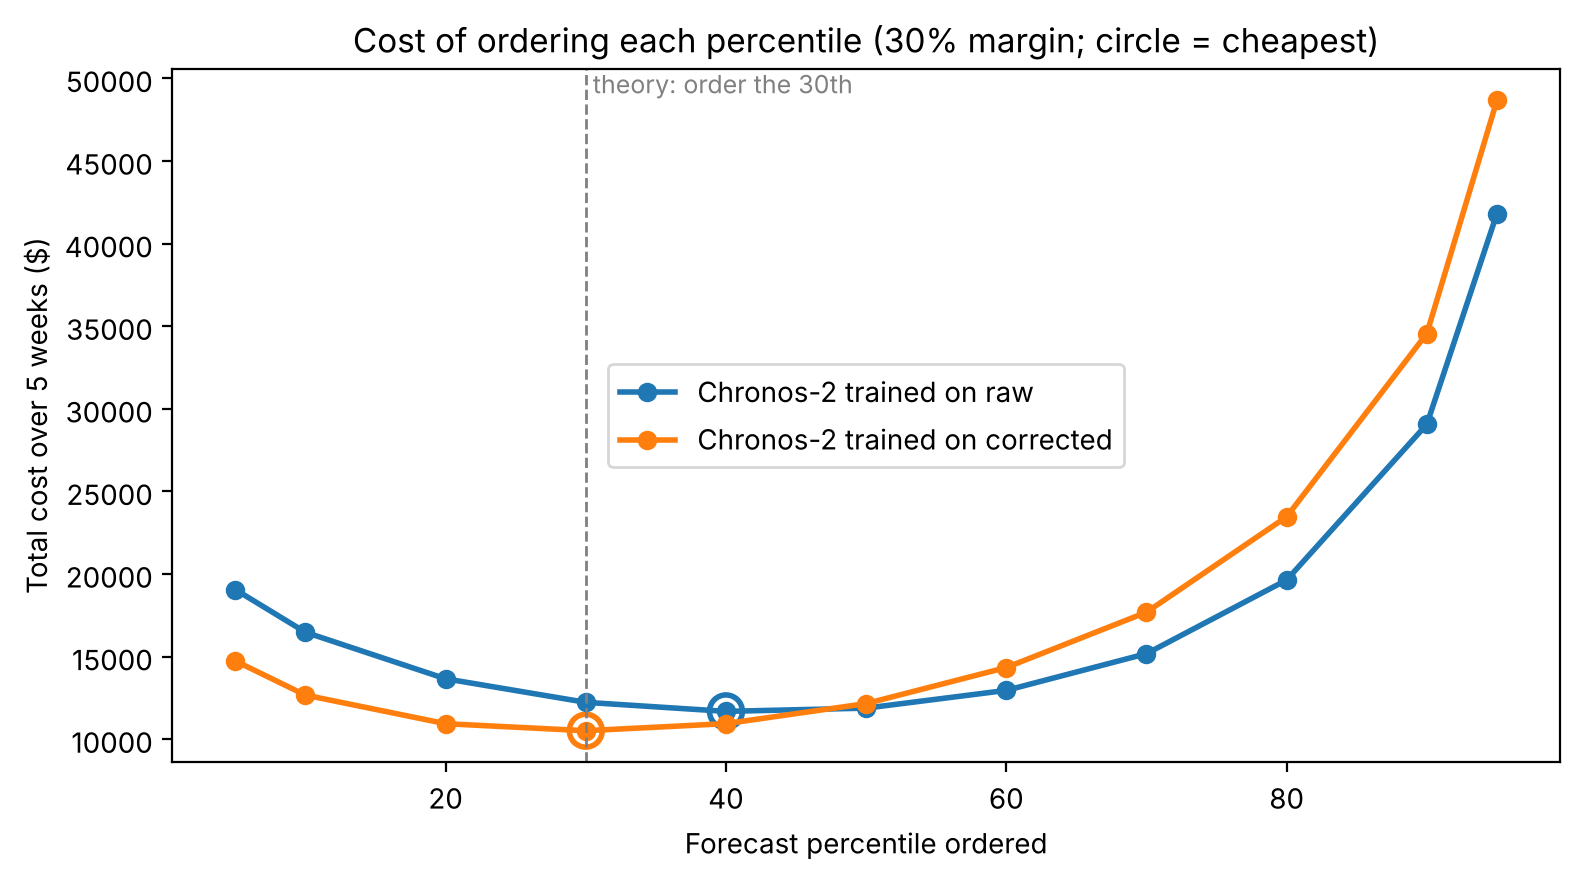

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for v, color in [('raw', 'tab:blue'), ('corrected', 'tab:orange')]:
    c = curve[curve.version == v]
    ax.plot(c.percentile, c.total_cost_usd, marker='o', color=color, lw=2, label=f'Chronos-2 trained on {v}')
    b = c.loc[c.total_cost_usd.idxmin()]
    ax.scatter([b.percentile], [b.total_cost_usd], s=140, facecolors='none', edgecolors=color, lw=2)
ax.axvline(TAU * 100, color='gray', ls='--', lw=1)
ax.text(TAU * 100, ax.get_ylim()[1], ' theory: order the 30th', va='top', fontsize=9, color='gray')
ax.set_xlabel('Forecast percentile ordered'); ax.set_ylabel('Total cost over 5 weeks ($)')
ax.set_title('Cost of ordering each percentile (30% margin; circle = cheapest)')
ax.legend(); plt.tight_layout()
plt.savefig('figures/stream5_cost_by_percentile.png', dpi=150); plt.show()

## Step 8: Does the answer depend on the margin, or on what we call "true demand"?
**Margins.** We rerun everything at 20% and 40% margins (order the 20th / 40th percentile).

**True demand.** Corrected demand is an estimate, and the corrected models were trained on that same estimate, which could flatter them. So we also score against two other versions of the truth, taken from stream 4's error range:
- **Low:** true demand = recorded sales. This assumes nobody who found an empty shelf would have bought anything. It is the most favorable case for raw forecasts.
- **High:** on stockout days, sales are scaled up by the share of the day the shelf was stocked, using each product's usual hourly pattern from in-stock hours before May 8 (stream 4, Step 15). The share is floored at 0.3 so a short in-stock window can't blow up the estimate.

If corrected still wins under the low truth, the gain is not just the corrected models grading their own homework.

In [15]:
# High version of true demand (stream 4's upper bound)
h = pd.read_parquet(PROC_DIR / 'hourly_demand_v1.parquet', columns=['series_id', 'dt', 'hour', 'sales', 'out_of_stock'])
h['dt'] = pd.to_datetime(h['dt'])
prof = h[(h.dt <= '2024-05-07') & (h.out_of_stock == 0)].groupby(['series_id', 'hour']).sales.mean().rename('m').reset_index()
prof['share'] = prof.m / prof.groupby('series_id').m.transform('sum')
ht = h[h.dt.isin(info.dt.unique()) & (h.out_of_stock == 0)].merge(prof[['series_id', 'hour', 'share']], on=['series_id', 'hour'], how='left')
ht['share'] = ht.share.fillna(0)
obs = ht.groupby(['series_id', 'dt']).agg(obs_sales=('sales', 'sum'), obs_share=('share', 'sum')).reset_index()
truth_hi = info.merge(obs, on=['series_id', 'dt'], how='left').fillna({'obs_sales': 0, 'obs_share': 0})
so = truth_hi.oos_hours > 0
truth_hi['demand_high'] = np.where(so, np.maximum(truth_hi.sales, truth_hi.obs_sales / np.maximum(truth_hi.obs_share, 0.3)), truth_hi.sales)
truth_hi = truth_hi[['series_id', 'dt', 'demand_high']]
del h, ht

t = info.merge(truth_hi, on=['series_id', 'dt'])
print(f"Total true demand over 5 weeks: low (sales) {t.sales.sum():,.0f} | corrected (main) {t.demand.sum():,.0f} | high {t.demand_high.sum():,.0f}")

Total true demand over 5 weeks: low (sales) 71,707 | corrected (main) 82,708 | high 83,447


In [16]:
TRUTHS = {'low (= sales)': 'sales', 'main (corrected v1)': 'demand', 'high (scaled)': 'demand_high'}
sens = []
for m in MARGINS:
    o = make_orders(costs(m)[2]).merge(truth_hi, on=['series_id', 'dt'])
    for tname, tcol in TRUTHS.items():
        g = gain_table(summarize(simulate(o, margin=m, truth_col=tcol))).reset_index()
        sens.append(g.assign(margin=m, truth=tname))
sens = pd.concat(sens, ignore_index=True)

nv = sens[sens.policy == 'newsvendor']
print("Gain from correcting (newsvendor rule), % of raw cost. Rows: model and margin. Columns: which truth.")
display(nv.pivot_table(index=['model', 'margin'], columns='truth', values='gain (%)')[list(TRUTHS)].round(3))
print("Same, in dollars over 5 weeks x 2,000 products:")
display(nv.pivot_table(index=['model', 'margin'], columns='truth', values='gain ($)')[list(TRUTHS)].round(0))

Gain from correcting (newsvendor rule), % of raw cost. Rows: model and margin. Columns: which truth.


truth                  low (= sales)  main (corrected v1)  high (scaled)
model          margin                                                   
chronos2       0.2            -0.075                0.142          0.022
               0.3            -0.048                0.140          0.042
               0.4            -0.030                0.141          0.056
lightgbm       0.2            -0.063                0.122          0.022
               0.3            -0.014                0.138          0.058
               0.4             0.009                0.145          0.076
seasonal_naive 0.2            -0.147                0.013         -0.057
               0.3            -0.108                0.037         -0.022
               0.4            -0.076                0.061          0.007

Same, in dollars over 5 weeks x 2,000 products:


truth                  low (= sales)  main (corrected v1)  high (scaled)
model          margin                                                   
chronos2       0.2            -665.0               1362.0          235.0
               0.3            -531.0               1718.0          569.0
               0.4            -384.0               1978.0          887.0
lightgbm       0.2            -574.0               1212.0          242.0
               0.3            -163.0               1773.0          830.0
               0.4             115.0               2137.0         1271.0
seasonal_naive 0.2           -1648.0                151.0         -711.0
               0.3           -1491.0                534.0         -355.0
               0.4           -1162.0                997.0          130.0

In [17]:
# Point-forecast rule under the three truths (30% margin), for comparison
pt = sens[(sens.policy == 'point') & (sens.margin == MARGIN)]
pt.pivot_table(index='model', columns='truth', values='gain (%)')[list(TRUTHS)].round(3)

truth,low (= sales),main (corrected v1),high (scaled)
model,,,
chronos2,-0.212,-0.023,-0.087
gru,-0.103,0.025,-0.024
lightgbm,-0.191,-0.026,-0.073
seasonal_naive,-0.190,-0.042,-0.089


## Step 9: Where does correcting pay off?
Stream 2 found correction helps forecasts most for products that stock out often. Here is the same split in dollars (newsvendor rule, 30% margin, main truth). Products are grouped low / medium / high by their stockout rate in training.

In [18]:
nvs = sim[sim.policy == 'newsvendor']
band = summarize(nvs, by=('stockout_band', 'model', 'version'))[['total_cost_usd', 'demand_units']]
band = band.total_cost_usd.unstack('version')
band['gain ($)'] = band.raw - band.corrected
band['gain (%)'] = band['gain ($)'] / band.raw
band = band.reindex(['low', 'medium', 'high'], level='stockout_band')
band.round(3)

version                       corrected       raw  gain ($)  gain (%)
stockout_band model                                                  
low           chronos2         3060.870  3254.217   193.347     0.059
              lightgbm         3140.901  3199.701    58.801     0.018
              seasonal_naive   4154.490  4169.140    14.650     0.004
medium        chronos2         3192.057  3445.041   252.985     0.073
              lightgbm         3296.607  3522.420   225.813     0.064
              seasonal_naive   4203.733  4252.808    49.075     0.012
high          chronos2         4264.899  5536.455  1271.556     0.230
              lightgbm         4638.027  6126.814  1488.787     0.243
              seasonal_naive   5455.935  5926.495   470.560     0.079

## Step 10: Charts
**Chart 1:** total cost split into lost sales and waste, for each model, raw vs. corrected (newsvendor rule; GRU uses its point forecast).

**Chart 2:** gain from correcting under the three versions of true demand, by margin, for Chronos-2 and LightGBM.

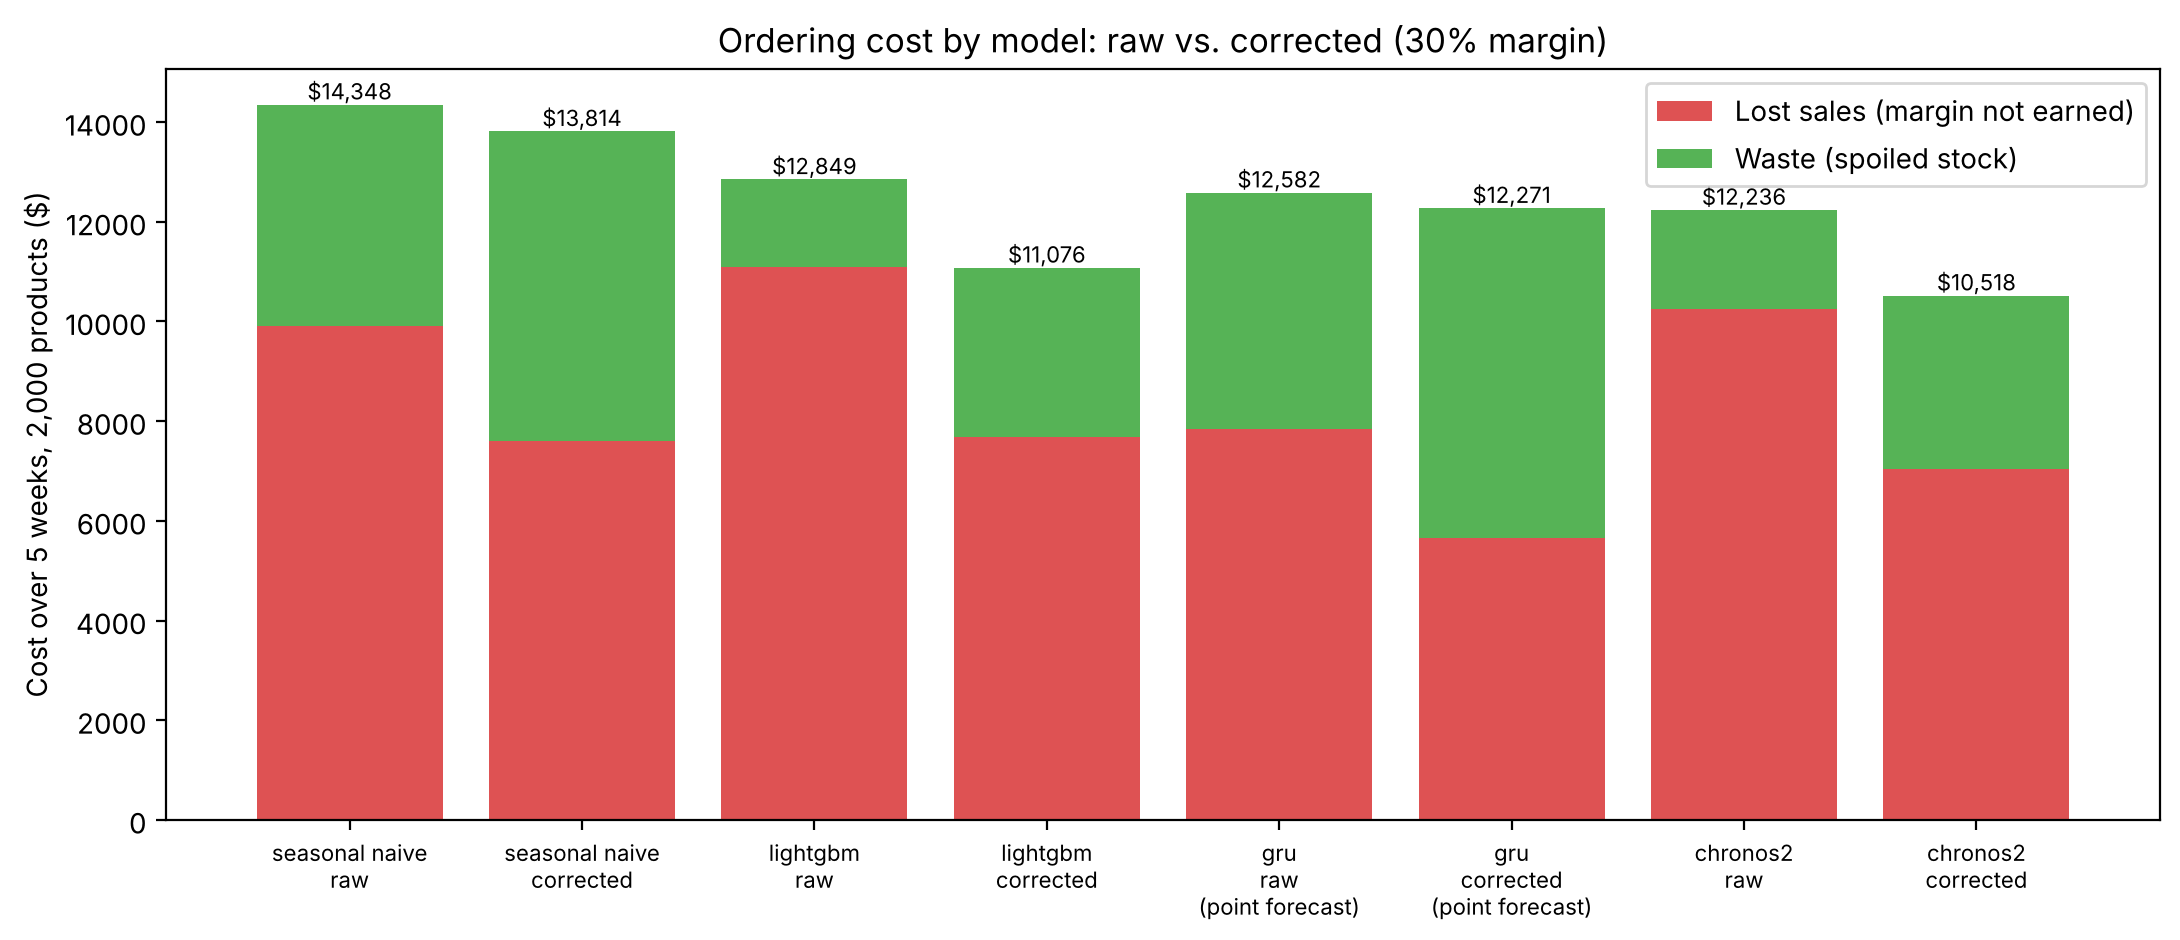

In [19]:
plot = (sim[sim.main_rule & sim.version.isin(['raw', 'corrected'])]
        .groupby(['model', 'version'])[['lost_sales_usd', 'waste_usd']].sum())
labels, lost, waste = [], [], []
for m in MODEL_ORDER:
    for v in ['raw', 'corrected']:
        r = plot.loc[(m, v)]
        labels.append(f"{m.replace('_', ' ')}\n{v}" + ('\n(point forecast)' if m == 'gru' else '')); lost.append(r.lost_sales_usd); waste.append(r.waste_usd)
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(x, lost, color='tab:red', alpha=0.8, label='Lost sales (margin not earned)')
ax.bar(x, waste, bottom=lost, color='tab:green', alpha=0.8, label='Waste (spoiled stock)')
for i, (a, b) in enumerate(zip(lost, waste)):
    ax.text(i, a + b, f'${a + b:,.0f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel('Cost over 5 weeks, 2,000 products ($)')
ax.set_title('Ordering cost by model: raw vs. corrected (30% margin)')
ax.legend(); plt.tight_layout()
plt.savefig('figures/stream5_cost_by_model.png', dpi=150); plt.show()

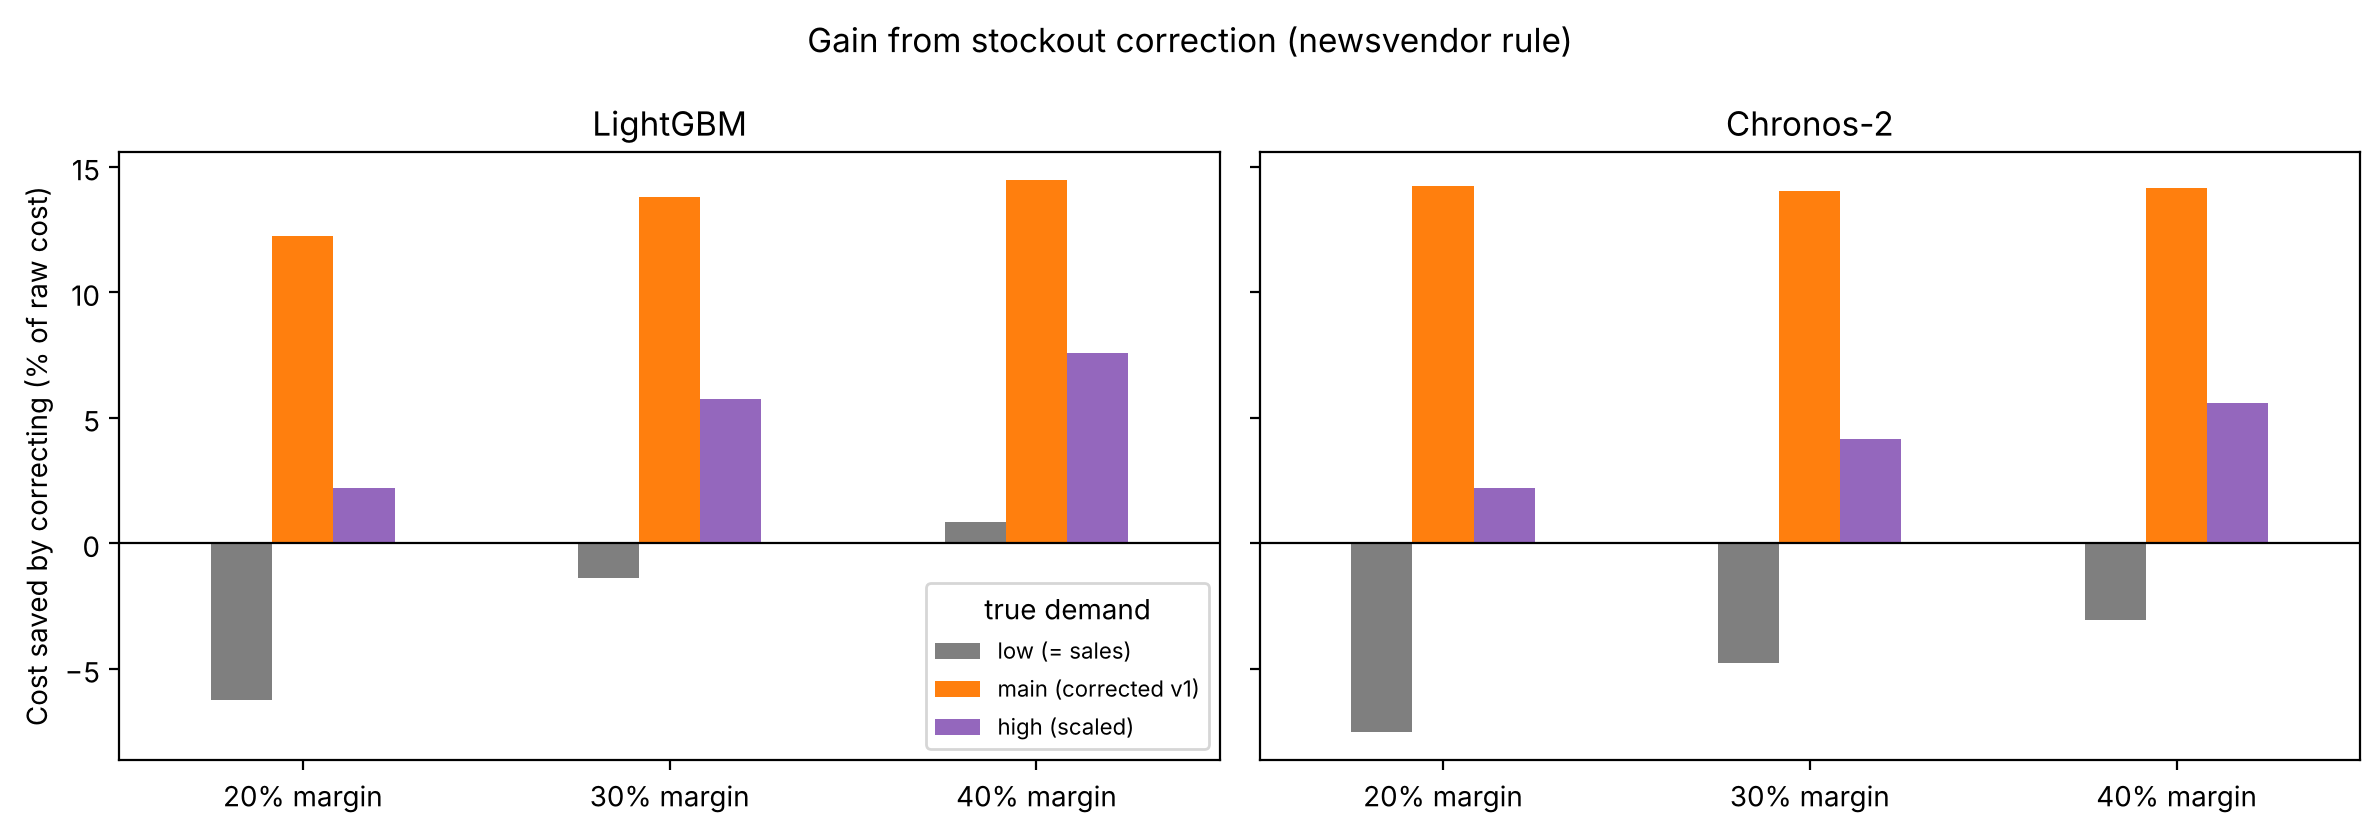

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, m in zip(axes, ['lightgbm', 'chronos2']):
    p = nv[nv.model == m].pivot_table(index='margin', columns='truth', values='gain (%)')[list(TRUTHS)] * 100
    p.index = [f'{int(i * 100)}% margin' for i in p.index]
    p.plot(kind='bar', ax=ax, color=['tab:gray', 'tab:orange', 'tab:purple'], rot=0)
    ax.axhline(0, color='black', lw=0.8); ax.set_title({'lightgbm': 'LightGBM', 'chronos2': 'Chronos-2'}[m])
    ax.set_ylabel('Cost saved by correcting (% of raw cost)'); ax.set_xlabel('')
    ax.legend(title='true demand', fontsize=8, loc='lower right') if m == 'lightgbm' else ax.get_legend().remove()
fig.suptitle('Gain from stockout correction (newsvendor rule)'); plt.tight_layout()
plt.savefig('figures/stream5_gain_sensitivity.png', dpi=150); plt.show()

## Step 11: Cross-check on stream 2's own file
Stream 2's `forecasts_stream2_v1.parquet` has LightGBM trained once (not per week) and scored on the validation and test weeks. If the conclusion holds there too, it doesn't depend on stream 4's retraining setup.

In [21]:
f2 = pd.read_parquet(PROC_DIR / 'forecasts_stream2_v1.parquet')
f2['dt'] = pd.to_datetime(f2['dt'])
o2 = []
for model in ['seasonal_naive', 'lightgbm']:
    g = f2[f2.model == model]
    o2.append(g.assign(order=g.forecast, policy='point'))
g = f2[f2.model == 'lightgbm']
o2.append(g.assign(order=interp_quantile(g, LGB_LEVELS, TAU), policy='newsvendor'))
sim2 = simulate(pd.concat(o2, ignore_index=True), margin=MARGIN)
cross = gain_table(summarize(sim2, by=('set', 'model', 'version', 'policy')))
cross.round(3)

raw cost ($)  corrected cost ($)  gain ($)  \
set   model          policy                                                   
test  lightgbm       newsvendor      2973.531            2553.657   419.874   
                     point           2575.021            2504.497    70.525   
      seasonal_naive point           3082.565            3284.254  -201.689   
valid lightgbm       newsvendor      5365.238            4556.372   808.866   
                     point           4748.136            4736.391    11.745   
      seasonal_naive point           5773.213            5921.201  -147.987   

                                 gain (%)  
set   model          policy                
test  lightgbm       newsvendor     0.141  
                     point          0.027  
      seasonal_naive point         -0.065  
valid lightgbm       newsvendor     0.151  
                     point          0.002  
      seasonal_naive point         -0.026

## Step 12: Save for the team
- **`results_stream5_v1.csv`** (Drive `processed/` and `results/tables/`): cost table per model, version and rule (30% margin, main truth).
- **`results_stream5_sensitivity_v1.csv`**: gain from correcting for every margin and truth.
- **`results_stream5_stability_v1.csv`**: weeks won, sign test and bootstrap ranges.
- **`results_stream5_by_week_v1.csv`**, **`results_stream5_percentile_curve_v1.csv`**: week-by-week costs and the Chronos-2 percentile curve.
- Figures: `figures/stream5_*.png`.

In [22]:
tables = {
    'results_stream5_v1.csv': main_table,
    'results_stream5_sensitivity_v1.csv': sens,
    'results_stream5_stability_v1.csv': stability,
    'results_stream5_by_week_v1.csv': wk_tab.reset_index(),
    'results_stream5_percentile_curve_v1.csv': curve,
}
for name, tab in tables.items():
    tab.to_csv(Path('results/tables') / name, index=False)
    try:
        tab.to_csv(PROC_DIR / name, index=False)
    except OSError as e:
        print('Could not write to Drive:', e)
print('Saved:', list(tables))

Saved: ['results_stream5_v1.csv', 'results_stream5_sensitivity_v1.csv', 'results_stream5_stability_v1.csv', 'results_stream5_by_week_v1.csv', 'results_stream5_percentile_curve_v1.csv']


## What we found
All numbers are totals over 2,000 products and 35 days (5 backtest weeks), with every unit valued at $1. Total true demand is about 82,700 units, so $1,000 is about 1.2% of sales.

1. **Correcting for stockouts saves money, but only if the store orders the right percentile.** With the newsvendor rule (order the 30th percentile at a 30% margin), training on corrected demand cuts ordering cost by **14%** for both Chronos-2 ($12,236 → $10,518) and LightGBM ($12,849 → $11,076). That's about **2 cents per dollar of sales**. It wins in 5 of 5 weeks (sign test p = 0.031), the product bootstrap range stays well above zero, and stream 2's own file gives the same 14 to 15%.
2. **If the store just orders the forecast, correcting costs money (−2 to −4%).** Corrected forecasts are higher. A spoiled unit costs $0.70 but a lost sale only $0.30, so ordering a higher median mostly adds waste. Correction and cost-aware ordering only pay off together.
3. **Corrected forecasts have honest ranges; raw ones don't.** For Chronos-2 corrected, the cheapest percentile is exactly the 30th, as theory predicts. Raw forecasts sit too low: their cheapest order is the 40th percentile, and even there they cost $11,689, still 10% more than corrected at the 30th.
4. **The size of the gain depends on how hidden demand is estimated.** The corrected models were trained on the same demand estimate we grade them on. Under the independent "high" estimate (sales scaled up by the in-stock share of the day), the gain shrinks to **4 to 6%** at a 30% margin (Chronos-2 $569, LightGBM $830), and to about 2% at a 20% margin. Under the extreme "no hidden demand at all" floor (true demand = recorded sales), correcting loses 1 to 5%. A fair summary is a **4 to 14% saving** for the two best models, positive under every realistic view of demand.
5. **The gain is concentrated in products that stock out often.** For the high-stockout third of products, correcting saves 23 to 24% (Chronos-2, LightGBM). For the low-stockout third it saves 2 to 6%.
6. **Better forecasts mean lower cost.** Chronos-2 corrected is the cheapest setup overall. Seasonal naive gains little from correcting (4%), and the GRU trained on censored-aware loss costs more than the plain corrected GRU (1 of 5 weeks won).
7. **The LightGBM shortcut is fine.** Drawing a straight line between the 10th and 50th percentiles to get the 30th adds 0.1% to cost for corrected forecasts and 2.7% for raw ones (tested on Chronos-2). So LightGBM's gain may be overstated by about $330 of its $1,773.

## Limitations
- **Prices are assumed.** Every unit is $1 with one margin for all products. Stream 3's second retailer (with real prices) can replace this later.
- **True demand is estimated.** The main numbers use corrected demand v1; Step 8 brackets them with a low and a high truth.
- **Lost sales cost only the margin.** Customers who leave and don't come back (lost goodwill) would make empty shelves costlier, which favors ordering more.
- **No shelf life beyond one day, no order minimums or pack sizes, no lead time** beyond the 7-day-ahead forecast.
- **LightGBM's 30th percentile is interpolated** between its 10th and 50th. The Chronos-2 check in Step 4 shows how much that costs.
- **GRU and TFT** have no forecast ranges in the hand-off files, so GRU is only tested with its point forecast and TFT (validation/test weeks only, in `forecasts_stream2_tft_v1.parquet`) is not included.

## Reuse and disclosure notes (for the final report)
- **Libraries:** pandas, numpy, scipy (sign test), matplotlib.
- **Pretrained models:** none run here. The Chronos-2 forecasts come from stream 4 (amazon/chronos-2).
- **Borrowed code:** the high-truth calculation follows stream 4's Step 15. The newsvendor critical ratio is the textbook result.
- **LLM use:** this notebook was drafted with AI assistance (Claude). Before submitting, write 1 to 2 paragraphs on what the AI produced vs. what you decided and checked (cost assumptions, true-demand choice, all-days scoring, the interpolation shortcut).

In [ ]:
# COLAB_ONLY
# Save this notebook to the team's GitHub repo, on its own branch.
from google.colab import userdata
%cd /content/stockout-aware-forecasting
NAME  = 'your-github-username'
EMAIL = 'your-github-email'
NOTEBOOK_PATH = '/content/drive/MyDrive/Final Project/stream5_ordering_simulation.ipynb'
token = userdata.get('GITHUB_TOKEN')

!git config user.name "{NAME}"
!git config user.email "{EMAIL}"
!git checkout -B stream5-simulation
!cp "{NOTEBOOK_PATH}" notebooks/stream5_ordering_simulation.ipynb
!git add notebooks/stream5_ordering_simulation.ipynb figures/stream5_*.png results/tables/results_stream5_*.csv
!git commit -m "Stream 5: ordering simulation, raw vs corrected in dollars"
!git push https://{token}@github.com/bulut19/stockout-aware-forecasting.git stream5-simulation